# Word Embeddings

## 1. Por que utilizar Embeddings? 

Para entender a importância dos Embeddings  precisamos considerar que as operações matemáticas das redes neurais tradicionais trabalham com representações numéricas. Por conta disso,  antes de processar um texto, precisamos convertê-lo em uma representação que possa ser utilizada.

A princípio, a primeira forma de contornar esse problema é atribuindo um identificador numérico a cada token presente nos dados de entrada. Entretanto, esse identificadores não expressam isolados as relações semânticas entre as palavras.

Imagine que a palavra "legal" recebe o ID 10 e que a palavra "bacana" recebe o ID 78.

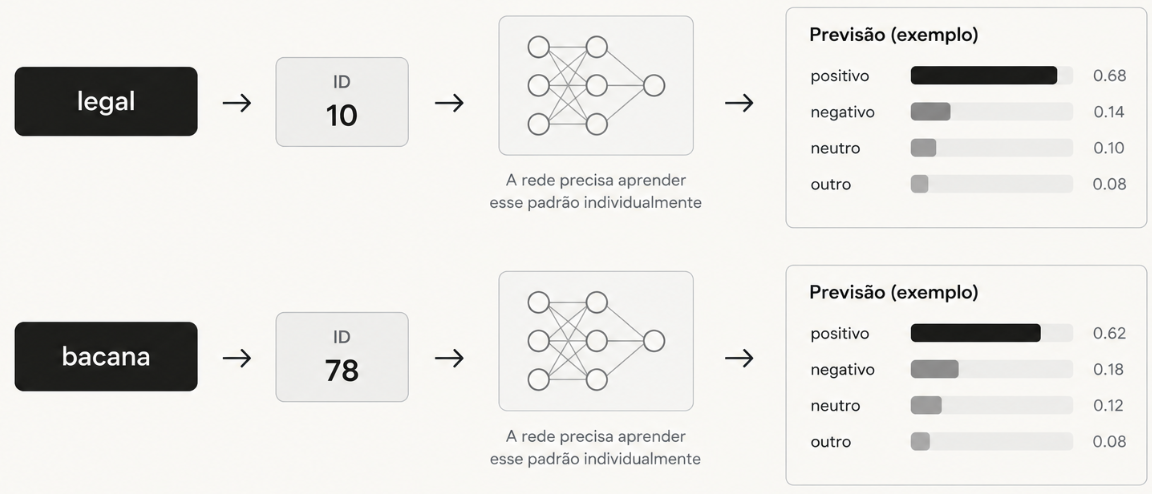

Embora essas palavras possam ter significados semelhantes, seus identificadores não representam essa relação. O modelo precisa aprender padrões a partir dos dados de treinamento, pois a similaridade semântica não está expressa nos próprios IDs.

Outro problema aparece quando consideramos palavras que possuem mais de um significado.

Considere outro exemplo: a palavra "manga" recebe o ID 12. Independente do contexto que ela for colocada ( sendo fruta ou parte de uma roupa ) ela terá o exato mesmo ID.

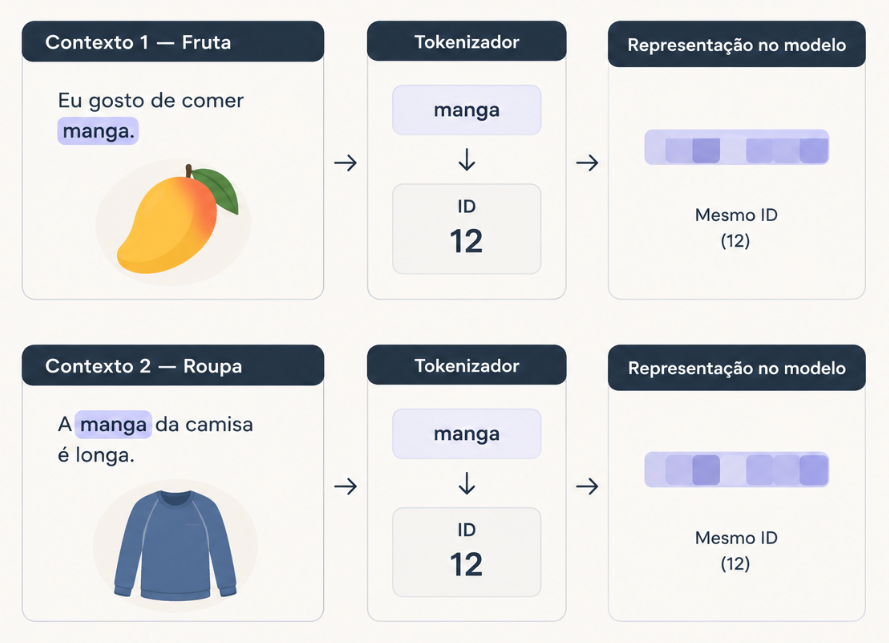

Por fim, existem outras técnicas para representar numéricamente palvras/textos como  One-Hot Encoding, Bag-Of-Words entre outras. Mas todas essas técnicas carecem de representação contextual e produzem vetores muito esparsos ( com muitos zeros ), o que tende a não ser a maneira mais eficiente do uso do espaço.

Caso as relações contextuais e entre palavras fossem capturadas e pudessemos  representar os tokens por meio de vetores densos e aprendíveis seria extremamente interessante, certo? 

Essas são justamente uma das principais motivações para utilizar embeddings.

## 2. O que é? 

Embeddings são representações vetorais aprendíveis associadas a tokens. No contexto de processamento de linguagem natural faz com que cada token seja representado por um vetor denso que atribui valores numéricos aleatórios a cada token inicialmente e durante o treinamento captura e atualiza esses valores considerando relações coontextuai e semânticas.

Em determinados modelo, ao capturar e representar essas relações, vetores semelhantes tendem a estar proximos no espaço dos embeddings. 

### 2.1. Vetores Densos

São vetores onde a maioria ou todos os elementos possuem valores diferentes de 0, no contexto dos embeddings esses vetores tem dimensão fixa e pode ser diferente do número de palavras do vocabulário.

*OBS*: O One-Hot encoding cria um vetor esparso com o número de dimensões igual ao tamanho do vocabulário. Apenas a posição correspondente ao token recebe o valor 1 e todas as demais recebem 0.

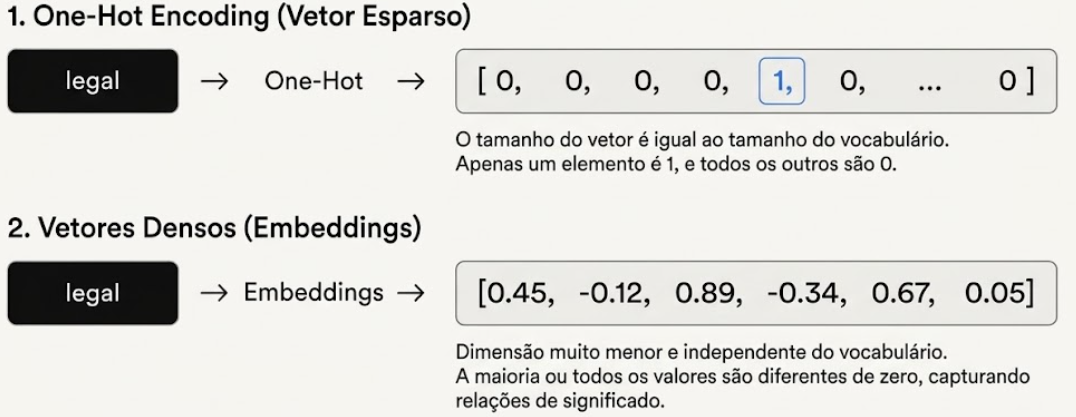

## 3. Espaço de Embedings

Como cada embedding é um vetor numérico, podemos representa-lo como um ponto em um espaço vetorial de n dimensões. Para podermos visualizar como se parece um espaço de embeddings, vamos considerar representações com 2 dimensões.

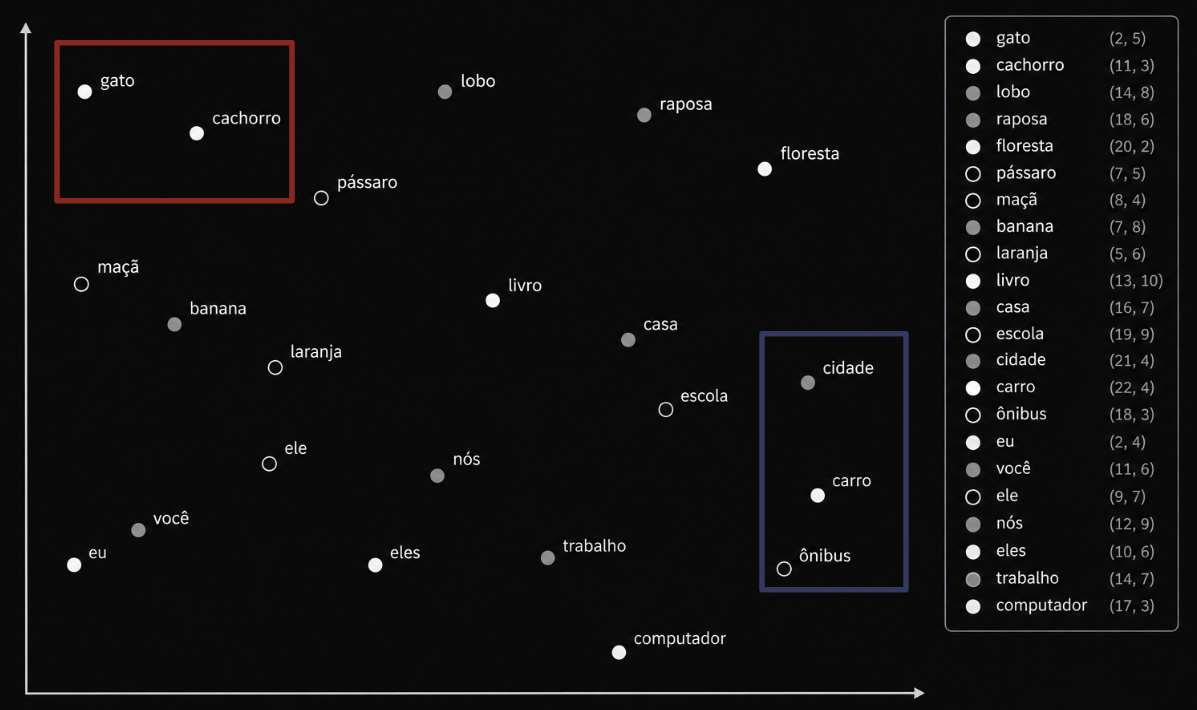

No contexto dessa projeção é possivel perceber que de fato palavras que possuem significados semelhantes ou pertencem a um mesmo campo semântico tendem a ficar próximas no espaço de embeddings, pois seus vetores podem apresentar maior similaridade.

É importante frisar que geralmente embeddings possuem centenas de dimensões e projeções com tão poucas dimensões podem não representar tão bem as relações. Mas a nível didático, utilizar 2 ou 3 dimensões é uma ótima forma de entender como se parecem.

Por fim, como dito antes, os embeddings iniciais não representam bem os tokens e durante o treinamento essas relações semânticas e contextuais são aprendidas e os valores numéricos atualizados.


In [ ]:
import math
import torch.nn as nn

c:\Users\Ian Guilherme Dev\Desktop\projetos-pessoais\transformer-scratch\.venv\Lib\site-packages\torch\_subclasses\functional_tensor.py:368: UserWarning: Failed to initialize NumPy: No module named 'numpy' (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:84.)
  cpu = _conversion_method_template(device=torch.device("cpu"))


EXEMPLOS:

- Se temos os indices [5, 12, 7, 20] -> [[vetor n dims], [vetor n dims], [vetor n dims], [vetor n dims]].
    - o que era [quantidade de tokens por sequencia] -> [quantidade tokens por sequencia, n dims].

In [ ]:
class Embedding(nn.Module):
    def __init__(
            self,
            num_embeddings,
            embedding_dim
        ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings, #numero de embeddings -> mesmo tamanho do vocabulário ( com n dimensões CADA)
            embedding_dim 
        )
        # matriz weight foi inicializada com valores iniciais aleatórios ( sem significado semântico útil ) -> ajustados no treinamento 
        
        self.embedding_dim = embedding_dim

    def forward(self, idxs):
        return self.embedding(idxs) * math.sqrt(self.embedding_dim) # o paper "Attention is All You Need" faz a implementação multiplicando pela raiz de d_model.]
        #retorna uma matriz [B, L, D]

##### Comentário sobre input e output do embedding:

Segundo a documentação do PyTorch sobre nn.Embedding, os inputs vem no formato ( * ) e os outputs ( * , H ), onde H -> dimensões do modelo.

EX:
- INPUT: [B, L] -> batch size, sequence len (numero de ids em uma sequência)
- OUTPUT: [B, L, D] -> no fim o número de dimensões dos embeddings também fica aparente.